# Fig. 4 — surface condensation on a spherical anchor

Composite of seven panels, built at `\textwidth` so LaTeX applies no rescaling.
Follows `FIGURE_STYLE.md`: all text at the caption size (9 pt printed), tick
labels 8 pt, panel letters Arial 12 pt, saved without `bbox_inches="tight"`.

| panel | content | from `viz-rouse.ipynb` |
|---|---|---|
| A | schematic: text drawn here, artwork `fig4_cartoon.svg` stamped underneath | — |
| B | Flory–Huggins graphical construction, $f(\phi)-f(\phi_\infty)$ | cell 137 |
| C | influence of curvature, same axes, three $R$ | cell 143 |
| D | surface volume fraction vs $c/c_{\rm sat}$, three $R$ | cell 149 (top) |
| E | surface volume fraction vs $c/c_{\rm sat}$, five $h_0$ | cell 146 (top) |
| F | Fisher rate vs $c/c_{\rm sat}$, three $R$ | cell 149 (bottom) |
| G | Fisher rate vs $c/c_{\rm sat}$, five $h_0$ | cell 146 (bottom) |

**Data.** Run `bash figure_production/fig4/run_fig4_solver.sh` from the repo root
first; it writes `data/20261004/{small_R,medium_R,large_R}/` and
`data/20261007/run{1..5}/demo_bvp_profiles.json`. Paths below are relative to
the repo root, so run this notebook from there (or adjust `REPO`).

In [97]:
import json, os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# The copied cells use paths like "data/20261004/..." relative to the repo root,
# so the notebook has to chdir there. Where the kernel starts is not something
# to rely on: Jupyter starts it in the notebook's directory, VS Code in whatever
# folder the workspace was opened at -- which may be several levels above the
# repo, or beside it. So look in three places, in order of reliability.

REPO_OVERRIDE = None        # set to the repo path to skip the search entirely,
                            # e.g. "/Users/mora/NextCloudCNRS/Code/droplet/Droplet"

SKIP = {"node_modules", "__pycache__", "venv", ".venv", "env", "build", "dist"}


def _is_repo(d):
    return (os.path.isfile(os.path.join(d, "Project.toml"))
            and os.path.isdir(os.path.join(d, "spec")))


def _up_from(d):
    """The nearest repo root at or above d."""
    d = os.path.abspath(d)
    for _ in range(8):
        if _is_repo(d):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            return None
        d = parent
    return None


def _down_from(base, max_depth=4):
    """The nearest repo root below base, breadth first so the shallowest wins."""
    level = [os.path.abspath(base)]
    for _ in range(max_depth):
        nxt = []
        for d in level:
            try:
                names = sorted(os.listdir(d))
            except OSError:
                continue
            for name in names:
                if name.startswith(".") or name in SKIP:
                    continue
                cand = os.path.join(d, name)
                if not os.path.isdir(cand) or os.path.islink(cand):
                    continue
                if _is_repo(cand):
                    return cand
                nxt.append(cand)
        level = nxt
    return None


def resolve_repo():
    """The directory holding Project.toml and spec/."""
    if REPO_OVERRIDE:
        if not _is_repo(REPO_OVERRIDE):
            raise RuntimeError("REPO_OVERRIDE is not the repo root: " + REPO_OVERRIDE)
        return REPO_OVERRIDE

    # 1. this notebook's own location -- VS Code exposes it, and it is the one
    #    answer that does not depend on where the kernel was started
    nb = globals().get("__vsc_ipynb_file__") or globals().get("__file__")
    if nb:
        found = _up_from(os.path.dirname(os.path.abspath(nb)))
        if found:
            return found

    # 2. at or above the working directory
    found = _up_from(os.getcwd())
    if found:
        return found

    # 3. below it, for a kernel started above the repo
    found = _down_from(os.getcwd())
    if found:
        return found

    raise RuntimeError(
        "repo root not found from %s -- expected a directory holding both "
        "Project.toml and spec/. Set REPO_OVERRIDE at the top of this cell to "
        "the repo path and re-run." % os.getcwd())


REPO = resolve_repo()
os.chdir(REPO)
print("working directory:", os.getcwd())

for p in ["data/20261004/large_R", "data/20261004/medium_R", "data/20261004/small_R",
          "data/20261007/run1", "data/20261007/run5"]:
    f = os.path.join(p, "demo_bvp_profiles.json")
    print(("  ok      " if os.path.exists(f) else "  MISSING ") + f)

working directory: /Users/mora/NextCloudCNRS/Code/droplet/Droplet
  ok      data/20261004/large_R/demo_bvp_profiles.json
  ok      data/20261004/medium_R/demo_bvp_profiles.json
  ok      data/20261004/small_R/demo_bvp_profiles.json
  ok      data/20261007/run1/demo_bvp_profiles.json
  ok      data/20261007/run5/demo_bvp_profiles.json


## Text rendering

`usetex` for Computer Modern, `amsmath` for `\dfrac`, with a loud fallback.

In [98]:
def use_latex():
    plt.rcParams.update({"text.usetex": True, "font.family": "serif",
                         "text.latex.preamble": r"\usepackage{amsmath}"})
    try:
        fig = plt.figure()
        fig.text(0.5, 0.5, r"$\dfrac{\dot{\mathcal{F}}_{\rm o}(c)}{k^+c_{\rm local}}$")
        fig.canvas.draw()
        plt.close(fig)
        return True
    except Exception as exc:
        plt.close("all")
        plt.rcParams.update({"text.usetex": False, "font.family": "sans-serif"})
        print("LaTeX unavailable, falling back to mathtext:",
              type(exc).__name__, str(exc).strip()[:120])
        return False


USETEX = use_latex()
print("usetex:", USETEX)

usetex: True


## Flory–Huggins model and calibration

Copied verbatim from `viz-rouse.ipynb` cells 128 and 135 — the only earlier
cells panels B–G depend on. (Cells 131–132, the image-based Klf4 fit, are not
needed.)

In [99]:
### Calibration to experimental concentrations

import numpy as np
from scipy.optimize import brentq

# --- Flory-Huggins per lattice site (kT=1), chain entropy on the solute only ---
def fb(phi, nb, chi):
    return phi/nb*np.log(phi) + (1-phi)*np.log(1-phi) + chi*phi*(1-phi)

def dfb(phi, nb, chi):
    return (np.log(phi)+1)/nb - (np.log(1-phi)+1) + chi*(1-2*phi)

def omega(phi, phi_inf, nb, chi):
    return fb(phi, nb, chi) - fb(phi_inf, nb, chi) - dfb(phi_inf, nb, chi) * (phi - phi_inf)

def excess_free_energy(z, R, kappa, omega_b, phi, phi_inf, nb, chi):
    dphi = np.gradient(phi, z)
    integrand = 4 * np.pi * (z + R)**2 * (omega(phi, phi_inf, nb, chi) + (kappa/2)*(dphi)**2)
    surface_term = 4 * np.pi * R**2 * omega_b * (phi[0] - phi_inf)
    return np.trapz(integrand, z) + surface_term

def _spinodal(nb, chi):
    a = 2*chi*nb; b = (nb-1) - a; disc = b*b - 4*a
    if disc <= 0: return None
    return (-b-np.sqrt(disc))/(2*a), (-b+np.sqrt(disc))/(2*a)

# --- Common tangent: given the dilute branch phi_sat, solve for (chi, phi_dense) ---
# Equal exchange potential fixes chi explicitly for any trial phi_dense, so only
# the equal-pressure condition is root-found -> 1D and bracketed.
def calibrate(phi_sat, nb, eps=1e-12):
    A = lambda p: (np.log(p)+1)/nb - (np.log(1-p)+1)
    chi_of = lambda p2: (A(phi_sat) - A(p2)) / (2*(phi_sat - p2))
    def press(p2):
        chi = chi_of(p2)
        Pi = lambda p: p*dfb(p, nb, chi) - fb(p, nb, chi)
        return Pi(phi_sat) - Pi(p2)
    grid = np.linspace(phi_sat + 1e-6, 1 - eps, 20000)
    v = np.array([press(p) for p in grid])
    k = np.where(v[:-1]*v[1:] < 0)[0]
    if len(k) == 0: raise RuntimeError("no common tangent found")
    p2 = brentq(press, grid[k[-1]], grid[k[-1]+1], xtol=1e-14)
    return chi_of(p2), p2

# --- Cahn construction: range of |h0| admitting two surface solutions at phi_inf ---
# Extrema of dF are roots of dfb(p) = dfb(phi_inf), bracketed by the spinodals.
def h0_range(phi_inf, nb, chi, kappa=1.0, eps=1e-12):
    sp = _spinodal(nb, chi)
    if sp is None: return None
    s1, s2 = sp
    dmu = dfb(phi_inf, nb, chi)
    dF  = lambda p: fb(p, nb, chi) - fb(phi_inf, nb, chi) - dmu*(p - phi_inf)
    g   = lambda p: dfb(p, nb, chi) - dmu                # = dF'(p)
    try:
        p_max = brentq(g, max(s1, phi_inf*(1+1e-9)), s2, xtol=1e-14)   # barrier top
        p_min = brentq(g, s2, 1 - eps, xtol=1e-14)                     # dense local min
    except ValueError:
        return None                                      # metastable dense state gone
    lo, hi = max(dF(p_min), 0.0), dF(p_max)
    if hi <= lo: return None
    return np.sqrt(2*kappa*lo), np.sqrt(2*kappa*hi), p_max, p_min

# --- concentration map (independent of the lattice choice) ---
                                   # nm^3
def to_phi(c_nM, v_tf): 
    return c_nM*1e-9*6.022e23/1e24*v_tf

def to_nM(phi, v_tf):  
    return phi/v_tf*1e24/6.022e23*1e9

In [100]:
v_tf   = 67.0      # Klf4 protein, nm^3
kT = 1.0
inds = [0, 10, 25, 45]
nb = 2233  # Klf4
# nb = 1000          # consistent with both v_tf / v_water and the measured c_dense
c_sat = 2000     # nanomolar
c_pw = c_sat/4  # nanomolar
c_dense = 2.4e6
delta_mu = kT*np.log(c_sat/c_pw)
phi_sat = to_phi(c_sat, v_tf)
phi_pw = to_phi(c_pw, v_tf)
phi_dense = to_phi(c_dense, v_tf)

chi, phi_d = calibrate(phi_sat, nb)
print("Chi (calibrated given nb): ", chi)
print("phi_dense (calibrated given nb): ", phi_d)
print("phi_dense (MD fit): ", phi_dense)
print("phi sat (given): ", phi_sat)
print("phi pw (given): ", phi_pw)

R = 40   # nm
print("R: ", R)

# vol fracs at edges of interface
phi_10 = phi_sat + 0.1*(phi_d - phi_sat)
phi_90 = phi_sat + 0.9*(phi_d - phi_sat)

# interface width from omega integral on a plane at equilibrium
mu_sat = nb*dfb(phi_sat, nb, chi)
mu_d = nb*dfb(phi_d, nb, chi)
print("mus equal: ", mu_sat, mu_d)
# domega  = lambda p: fb(p, nb, chi) - fb(phi_sat, nb, chi) + mu_sat*(p - phi_sat)/nb # kBT/b
phis_interface = np.linspace(phi_10, phi_90, 10000)
_trapz = getattr(np, "trapezoid", None) or np.trapz   # numpy 1.x and 2.x
I = _trapz((2*omega(phis_interface, phi_sat, nb, chi))**(-0.5), phis_interface) # (b/kBT)^1/2
v_water = 0.0297   # nm^3 
b = v_water**(1/3)  # nm
l_interface_nm = 15.28  # nm
# l_interface_nm = 15.0  # nm
print("Site length (nm): ", b)
print("Interface length (nm): ", l_interface_nm)
print("Interface length (sites): ", l_interface_nm / b)
l_interface_sites = l_interface_nm / b  # b (lattice site length)
kappa = (l_interface_sites / I)**2  # kBT / b
kappa_nm = kappa / b
print("kappa (kBT / site length): ", kappa)
print("kappa (kBT / nm): ", kappa_nm)

h0_lo, h0_hi, _, _ = h0_range(phi_pw, nb, chi, kappa=kappa, eps=1e-12)
print("h0_lo (kBT / site^2): ", h0_lo, "\nh0_hi (kBT / site^2): ", h0_hi)
print("h0_lo (kBT / nm^2): ", h0_lo/b**2, "\nh0_hi (kBT / nm^2): ", h0_hi/b**2)
print("kappa / h0_lo (sites): ", kappa / h0_lo)
# agreement with surface tension measurements
kBT = 4.11e-21 # J
phis_surf_tension = np.linspace(phi_sat, phi_d-1e-5, 5000)   # full range
I2 = _trapz((2*kappa*omega(phis_surf_tension, phi_sat, nb, chi))**0.5, phis_surf_tension)
S = I2 * kBT * 1e18 * 1e6 / b**2
print("Surface tension (muN/m): ", S)   # muN/m
print("Surface energy (kBT): ", 4*np.pi*R**2*I2 / b**2)   # muN/m

Chi (calibrated given nb):  0.5447880606274295
phi_dense (calibrated given nb):  0.11203620701580225
phi_dense (MD fit):  0.09683376000000003
phi sat (given):  8.069480000000001e-05
phi pw (given):  2.0173700000000003e-05
R:  40
mus equal:  -1024.9292306238624 -1024.9292306238624
Site length (nm):  0.3096840346369102
Interface length (nm):  15.28
Interface length (sites):  49.34061265998124
kappa (kBT / site length):  10.113883687600339
kappa (kBT / nm):  32.658718423952294
h0_lo (kBT / site^2):  0.03571078088392902 
h0_hi (kBT / site^2):  0.03604832447470795
h0_lo (kBT / nm^2):  0.3723588789282754 
h0_hi (kBT / nm^2):  0.375878470209698
kappa / h0_lo (sites):  283.2165367784468
Surface tension (muN/m):  85.2272784897929
Surface energy (kBT):  416.93335978820005


## Figure geometry

`\textwidth` = 481.9 pt, so building at that width means scale factor 1 and the
sizes below are the printed sizes. Heights are explicit in points: adjust
`H_A` (panel A's band, sized for the schematic you will paste in) and the three
`H_ROW_*` to taste — nothing else needs touching.

In [ ]:
PT_CAPTION, PT_TICK, PT_LETTER = 9, 8, 12      # printed sizes (FIGURE_STYLE.md)

# Stroke weights, in printed points. The same numbers appear in fig2 and
# fig3 (scaled there by their own SCALE) so the three figures are one set.
# LW is a data curve, LW_AUX a reference line or legend key.
# Measured off the PDFs: Tarek's original Fig. 4 prints its curves at
# 0.50 pt and fig2 draws its frame and ticks at 0.49 pt. One weight for
# everything, so no element is heavier than the originals.
LW, LW_AUX, LW_AXES = 0.5, 0.4, 0.5

# Construction markers, 30% smaller across: MS_LIN is the diameter factor,
# and scatter sizes are areas, so they take its square.
MS_LIN = 0.70
MS_AREA = MS_LIN ** 2

# Legend placement. LEG_PAD is the gap from the axes box (small = pushed
# into the corner), LEG_HANDLE the length of the line sample, LEG_COLSP
# the gap between columns. The last two are short so D and E can use few
# rows: widen them and fit_legend will fall back to more rows.
LEG_PAD, LEG_HANDLE, LEG_COLSP = 0.1, 1.6, 0.8
LEG_HANDLE_E = 0.6          # E only: anything longer forces one column

W = 481.9                   # \textwidth, in points
L1, L2 = 50.0, 50.0         # y-label + tick labels, left and right columns
GAP = 10.0                  # between the columns
# panel C's colorbar. CB_LAB was 24 pt: tick labels plus a rotated axis
# label beside the bar. The label now sits on top, so only the tick labels
# need room -- but they still do, or they are clipped at the page edge.
CB_PAD, CB_W, CB_LAB = 4.0, 7.0, 14.0
RIGHT = 6.0                 # the top label overhangs the bar by ~9 pt
AXW = (W - L1 - L2 - GAP - RIGHT - CB_PAD - CB_W - CB_LAB) / 2

PAD_T, PAD_B = 1.0, 2.0
LETTER_H = 21.0             # each letter's line, and the air above its axes
H_A = 96.0                  # panel A: text + the space you will paste into
GAP_A = 8.0                 # between panel A and the B/C row
GAP_ROW = 6.0               # between successive plot rows
H_ROW_BC, XLAB_BC = 100.0, 26.0
H_ROW_DE, XLAB_DE = 90.0, 26.0
H_ROW_FG, XLAB_FG = 90.0, 28.0

# A carries its letter inside its own band (top left, beside the title), so
# it needs no separate letter line
H = (PAD_T + H_A + GAP_A
     + LETTER_H + H_ROW_BC + XLAB_BC + GAP_ROW
     + LETTER_H + H_ROW_DE + XLAB_DE + GAP_ROW
     + LETTER_H + H_ROW_FG + XLAB_FG + PAD_B)

x_left, x_right = L1, L1 + AXW + GAP + L2
x_cb = x_right + AXW + CB_PAD

y = H - PAD_T
yA_top = y;  yA_bot = yA_top - H_A;  y = yA_bot - GAP_A
y1_let = y - LETTER_H;  y1_bot = y1_let - H_ROW_BC;  y = y1_bot - XLAB_BC - GAP_ROW
y2_let = y - LETTER_H;  y2_bot = y2_let - H_ROW_DE;  y = y2_bot - XLAB_DE - GAP_ROW
y3_let = y - LETTER_H;  y3_bot = y3_let - H_ROW_FG

RC = {
    "font.size": PT_CAPTION, "axes.labelsize": PT_CAPTION,
    "axes.titlesize": PT_CAPTION, "legend.fontsize": PT_CAPTION,
    "xtick.labelsize": PT_TICK, "ytick.labelsize": PT_TICK,
    # all four spines, as in the originals -- the legends are placed
    # against this box
    "axes.spines.top": True, "axes.spines.right": True,
    "lines.linewidth": LW,
    # the frame and ticks were 0.8 pt, 1.6x fig2's, and the restored box
    # doubled how much of that ink is on the page
    "axes.linewidth": LW_AXES,
    "xtick.major.width": LW_AXES, "ytick.major.width": LW_AXES,
    "xtick.minor.width": LW_AUX, "ytick.minor.width": LW_AUX,
    # pull the axis labels in towards the ticks, so the panel letters on
    # the far left of each column have room
    "axes.labelpad": 1.5,
}


# Paired panels share limits and ticks exactly, so the two halves of a row can
# be read against each other. Set here, applied through the replace tables.
BC_XLIM, BC_YLIM = (0.0, 0.165), (0.0, 0.005)     # f(phi) - f(phi_inf)
# 0.165, not 0.16: B's rightmost construction marker sits at phi = 0.1598
# and the frame would otherwise cut it in half
BC_XTICKS = [0.0, 0.05, 0.10, 0.15]
DE_XLIM, DE_YLIM = (0.0, 1.0), (0.0, 0.2)         # surface volume fraction
DE_XTICKS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
FG_XLIM, FG_XTICKS = DE_XLIM, DE_XTICKS           # Fisher rate, same abscissa


def _rect(x, yb, w, h):
    return [x / W, yb / H, w / W, h / H]


# ---- panel A's cartoon ----------------------------------------------------
# fig4/fig4_cartoon.svg is stamped into the saved PDF by the last cell;
# panel A itself carries only the type. Placement follows the reference
# assembly (225 x 237 pt): the drawing's COLOURED extent -- the only part of
# panel A that is not type, hence the only landmark the two files share --
# spans 39.84%..80.32% of the figure width, its top 1.80 pt below the top edge
# at that page size. Measured in both by thresholding colour saturation; the
# aspect ratios agree to 1% (2.456 vs 2.482), which is what confirms the match.
CART_X0F, CART_X1F = 0.3984, 0.8032
CART_TOP_PT = 1.80 * (W / 225.0)
VB_W, VB_H = 184.34, 86.55                  # the SVG's viewBox
INK = (9.750, 7.750, 171.375, 72.875)       # coloured box within it
CART_S = (CART_X1F - CART_X0F) * W / (INK[2] - INK[0])


def ptA(x_pt, y_top_pt):
    """Figure points (x from the left, y from the TOP) -> panel A axes coords."""
    return x_pt / W, ((H - y_top_pt) - yA_bot) / H_A


def cart(u, v):
    """A point in the SVG's own viewBox -> panel A axes coords, so the labels
    are anchored to the drawing rather than guessed; they follow it if its
    size or position changes."""
    return ptA(CART_X0F * W + CART_S * (u - INK[0]),
               CART_TOP_PT + CART_S * (v - INK[1]))


def fit_legend(ax, ncols, handles=None, labels=None, max_w=1.0, **kw):
    """Draw the legend with the first column count in `ncols` whose box
    fits inside the axes. Measured, not guessed: the width depends on the
    labels, the font and whether usetex is live, none of which are known
    when the number is written."""
    def build(nc):
        return (ax.legend(ncol=nc, **kw) if handles is None
                else ax.legend(handles, labels, ncol=nc, **kw))

    best = ncols[-1]
    for nc in ncols:
        lg = build(nc)
        ax.figure.canvas.draw()
        bb = lg.get_window_extent().transformed(ax.transAxes.inverted())
        if bb.width <= max_w:
            best = nc
            break
    return build(best)


print("figure %.1f x %.1f pt = %.3f x %.3f in" % (W, H, W / 72, H / 72))

figure 481.9 x 542.0 pt = 6.693 x 7.528 in


## The composite

Panels are created first, then each copied block draws into them.

(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

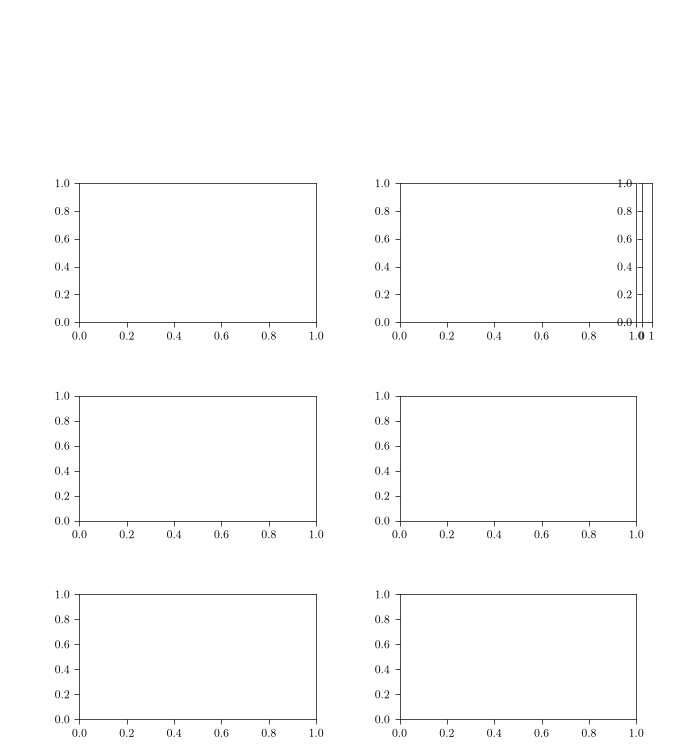

In [102]:
plt.rcParams.update(RC)
fig4 = plt.figure(figsize=(W / 72, H / 72))

pA = fig4.add_axes(_rect(0.0, yA_bot, W, H_A))      # schematic: text only
pB = fig4.add_axes(_rect(x_left,  y1_bot, AXW, H_ROW_BC))
pC = fig4.add_axes(_rect(x_right, y1_bot, AXW, H_ROW_BC))
cbC = fig4.add_axes(_rect(x_cb,   y1_bot, CB_W, H_ROW_BC))
pD = fig4.add_axes(_rect(x_left,  y2_bot, AXW, H_ROW_DE))
pE = fig4.add_axes(_rect(x_right, y2_bot, AXW, H_ROW_DE))
pF = fig4.add_axes(_rect(x_left,  y3_bot, AXW, H_ROW_FG))
pG = fig4.add_axes(_rect(x_right, y3_bot, AXW, H_ROW_FG))

# panel A is a blank canvas in 0..1 coordinates
pA.set_xlim(0, 1); pA.set_ylim(0, 1); pA.axis("off")

### Panel A — text

Everything in Tarek's panel A that is type rather than drawing, set in the same
Computer Modern at the caption size. The three blocks sit where they do in his
layout: the symbol key on the left, the sphere rendering in the middle (left
blank), the transcription model on the right.

The gaps are deliberate. `GRID = True` draws light guides at the reserved
regions so you can line the artwork up, then set it back to `False`.

In [103]:
GRID = False        # True -> show the reserved regions while pasting artwork

# ---- left: title + symbol key -------------------------------------------
AX0 = 0.055                 # left edge of the text column
pA.text(AX0, 0.99, "Flory-Huggins with\nsurface adsorption",
        ha="left", va="top", linespacing=1.4)

KEY = [r"$R$ : radius",
       r"$c$ : concentration",
       r"$\chi$ : bulk coupling",
       r"$h_0$ : surface attraction",
       r"$\nu$ : molecular volume ratio",
       r"$\kappa$ : interface curvature penalty"]
for i, s in enumerate(KEY):
    pA.text(AX0, 0.66 - i * 0.115, s, ha="left", va="center")

# ---- labels on the cartoon ----------------------------------------------
# (u, v) are coordinates in the SVG's own viewBox, read off the drawing: the
# Off circle is centred at (123, 58) with radius 10, the On circle at
# (169, 58), the upper arrow peaks near (143, 46) and the lower one near
# (145, 67), and the probe's leader line ends at (107, 55).
pA.text(*cart(146, 25), "Transcription model", ha="center", va="center")
pA.text(*cart(143, 43), r"$k^+c_{\rm local}$", ha="center", va="bottom")
# Off / On sit just above each small circle (top at v = 57.8), on the
# circles' common centre line (u = 122.6 and 169.3), baseline 1.2 viewBox
# units clear of it. Low rather than mid-gap: the big circle narrows towards
# its top (inner top v = 48.3), and a word this wide grazes the outline there.
# Anchored on the baseline, not va="center": the latter centres a box that
# reserves room for descenders these words lack, so the letters ride up.
_v_on = 57.8 - 1.2
pA.text(*cart(122.6, _v_on), "Off", ha="center", va="baseline")
pA.text(*cart(169.3, _v_on), "On", ha="center", va="baseline")
pA.text(*cart(145, 71), r"$k^-$", ha="center", va="top")
pA.text(*cart(95, 48), "Probe", ha="center", va="bottom")

# The leader line from the probe to the Off state is in the SVG, but it
# runs under the cloud's gradient and is washed out. Redraw it here, where
# it sits above the artwork; endpoints read off the viewBox.
_p0, _p1 = cart(68, 45.0), cart(107, 55.3)
pA.plot([_p0[0], _p1[0]], [_p0[1], _p1[1]], color="black", lw=LW_AUX,
        solid_capstyle="butt", zorder=4)

# the droplet's size bar: the SVG carries no arrow, so draw it here, spanning
# the circle's diameter just below the cloud -- the circle, outline included,
# runs u = 32.5..60.6 in the viewBox (centre 46.55), measured on a render
_xa, _xb = cart(32.5, 0)[0], cart(60.6, 0)[0]
_ya = ptA(0, 80.0)[1]
pA.annotate("", xy=(_xb, _ya), xytext=(_xa, _ya),
            arrowprops=dict(arrowstyle="<|-|>", lw=0.7, color="black",
                            shrinkA=0, shrinkB=0, mutation_scale=6))
pA.text((_xa + _xb) / 2, ptA(0, 89.0)[1], r"$\sim 30-60$ nm",
        ha="center", va="center")

if GRID:
    # the measured extent of the stamped artwork
    (gx0, gy0), (gx1, gy1) = cart(INK[0], INK[1]), cart(INK[2], INK[3])
    pA.add_patch(plt.Rectangle((gx0, gy1), gx1 - gx0, gy0 - gy1, fill=False,
                               lw=0.5, ls="dashed", color="0.7"))

### Panel B — graphical construction  (`viz-rouse.ipynb` cell 137)

In [ ]:
###### Graphical construction


# Bulk/surface parameters and phi_inf grid of the large_R run
# (spec/local/20261004/large_R/param.jl).  mu enters only through phi_inf, so the
# curves are omega(phi; phi_inf) = F(phi) - F(phi_inf) at fixed c/c_sat.  Multiples
# of mu_pw (as in the 20260821 figure) are meaningless here: mu ~ 1024 carries a
# large constant and mu_pw - mu_sat = ln 4.
d        = json.load(open("data/20261004/large_R/demo_bvp_profiles.json"))
p        = d["params"]["surface"]
nb, chi, kappa, h0 = p["nb"], p["chi_b"], p["kappa"], p["omega_b"]
phi_infs = np.array(d["phi_inf"])
binodal  = d["binodal"]
phis     = np.linspace(5e-9, 0.2, 20000)

# mu > mu_*, mu = mu_* (c_pw = c_sat/4, as in the kappa calibration),
# mu_sat < mu < mu_* (inside the bistable window of the run), mu = mu_sat
c_fracs = [0.14, 0.211, 0.312, 1.0]
inds    = [int(np.argmin(np.abs(phi_infs/binodal - t))) for t in c_fracs]
h_star  = h0_range(phi_infs[inds[1]], nb, chi, kappa=kappa)[0]   # dense min of the mu_* curve
init_energy_lo = h_star**2/(2*kappa)/v_water
hline   = h0**2/(2*kappa)/v_water                                         # the run's surface field


pB.axhline(hline, color="black", lw=LW_AUX,
           linestyle="dashed", alpha=0.5)

pB.fill_between(phis, 0, init_energy_lo, color="black", alpha=0.05)
pB.axhline(init_energy_lo, color="red", alpha=0.5, lw=LW_AUX)

labels = [r"$\mu > \mu_*$",
          r"$\mu = \mu_*$",
          r"$\mu_{\rm sat} < \mu < \mu_*$",
          r"$\mu = \mu_{\rm sat}$"]

for i, idx in enumerate(inds):
    dF = omega(phis, phi_infs[idx], nb, chi)/v_water
    pB.plot(phis, dF, lw=LW, color="black", alpha=(i+1)/4, label=labels[i])
    col = (1 - (i+1)/4,)*3   # opaque equivalent of the curve's black at alpha (i+1)/4

    if i == 2:
        xi = phis[np.where(np.diff(np.sign(dF - hline)) != 0)[0]]
        print(xi)
        yi = hline
        # lower-F film (the run's branch label at this phi_inf) filled, higher-F film
        # open, unstable middle root open with a dashed edge
        stable, meta = (xi[-1], xi[0]) if d["branch"][idx] == "thick" else (xi[0], xi[-1])
        pB.scatter(stable, yi, color=col, edgecolor="none", zorder=3, s=80 * MS_AREA)
        pB.scatter(meta, yi, facecolor="white", edgecolor=col, zorder=3, s=80 * MS_AREA)
        pB.scatter(xi[1], yi, facecolor="white", edgecolor=col, linestyle="--", zorder=3, s=80 * MS_AREA)

    elif i != 1:
        xi = phis[np.where(np.diff(np.sign(dF - init_energy_lo)) != 0)[0]]
        print(xi)
        yi = init_energy_lo
        pB.scatter(xi[0], yi, color=col, edgecolor="none", zorder=3, s=80 * MS_AREA)

pB.set_xlabel(r"Volume fraction $\phi$")
pB.set_ylabel(r"$f(\phi) - f(\phi_\infty) \; (k_BT / {\rm nm}^3)$")
# B and C share one set of limits and ticks (geometry cell)
pB.set_xlim(*BC_XLIM); pB.set_ylim(*BC_YLIM); pB.set_xticks(BC_XTICKS)

lg = pB.legend(loc="upper left", edgecolor="none", framealpha=0,
               borderaxespad=LEG_PAD, handlelength=LEG_HANDLE,
               handletextpad=0.4, labelspacing=0.45)

# the two h^2/2kappa keys as a second column, aligned row for row with the mu
# entries: the legend's own box is measured, so they follow it if it moves
fig4.canvas.draw()
_bb = lg.get_window_extent().transformed(pB.transAxes.inverted())
_n = max(len(lg.get_texts()), 1)
_rows = [_bb.y1 - (k + 0.5) * (_bb.y1 - _bb.y0) / _n for k in range(_n)]
# the key segments are drawn by hand, so give them the legend's own handle
# length and text gap -- in axes fractions, since handlelength is in font-size
# units and the axes is AXW points wide
_seg = LEG_HANDLE * PT_CAPTION / AXW
_txt = 0.4 * PT_CAPTION / AXW
_gap = 0.02
for _y, (_lab, _col, _ls, _lw) in zip(_rows,
        [(r"$h_*^2/2\kappa$", "red", "solid", LW_AUX),
         (r"$h_0^2/2\kappa$", "gray", "dashed", LW_AUX * 1.3)]):
    pB.plot((_bb.x1 + _gap, _bb.x1 + _gap + _seg), (_y, _y), color=_col,
            lw=_lw, linestyle=_ls, transform=pB.transAxes, clip_on=False)
    pB.text(_bb.x1 + _gap + _seg + _txt, _y, _lab,
            color=("black" if _col == "gray" else _col),
            transform=pB.transAxes, ha="left", va="center")

[0.04180209]
[0.04906246 0.0718836  0.11012551]
[0.15984799]


### Panel C — influence of curvature  (cell 143)

In [105]:
# xi = min{z : (phi(z) - phi_inf)/phi_inf < thresh}, with the crossing interpolated.
# The old expression, argmin(np.abs(phi - phi_inf)/phi_inf - 0.5), had np.abs closing
# before the -0.5, so it just sought the SMALLEST relative excess: it returned the
# first z where phi - phi_inf underflows to 0.0 (15-25% high), and clamped at L once
# the profile never gets there.  z = L is excluded below because the BVP pins it to
# phi_inf by the boundary condition -- a crossing there means L is too short to
# resolve xi, which is reported as nan rather than as xi = L.
def xi_of(z, phi, phi_inf, thresh=0.1):
    rel   = (phi - phi_inf) / phi_inf
    inner = rel[:-1]
    k = int(np.argmax(inner < thresh))
    if inner[k] >= thresh:
        return np.nan
    if k == 0:
        return 0.0
    r0, r1 = rel[k-1], rel[k]
    return z[k-1] + (thresh - r0) / (r1 - r0) * (z[k] - z[k-1])

# runs = [("data/20260821/large_R/demo_bvp_profiles.json", 200),
#         ("data/20260821/med_R/demo_bvp_profiles.json",    60),
#         ("data/20260821/small_R/demo_bvp_profiles.json",  20)]

# runs = [("data/20260825/demo_bvp_profiles.json", 200)]

# runs = [("data/20260825/large_R/demo_bvp_profiles.json", 200),
#         ("data/20260825/medium_R/demo_bvp_profiles.json",    60),
#         ("data/20260825/small_R/demo_bvp_profiles.json",  20)]

runs = [("data/20261004/large_R/demo_bvp_profiles.json", 200),
        ("data/20261004/medium_R/demo_bvp_profiles.json",    60),
        ("data/20261004/small_R/demo_bvp_profiles.json",  20)]

# Fractions along the swept phi_inf axis at which to draw the construction.  The mu
# values are read back OUT of the sweep rather than taken from the calibration cell
# above, so each marker necessarily sits on the curve the BVP actually solved at
# (the calibration cell is free to drift to another system without silently
# collapsing every marker onto the nearest sampled mu).
# sweep_fracs = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
sweep_fracs = np.array([0.305, 0.5, 0.9])

# Bulk parameters come from the run provenance for the same reason.  These globals
# stay bound to the first run, as before, since other cells read phi_surf / phi_full
# / phi_infs / z_full.
path      = runs[0][0]
d         = json.load(open(path))
p         = d["params"]["surface"]
bc_reg    = d["params"]["bvp"]["bc_reg"]
mu_infs   = np.array(d["mu_inf"])
phi_infs  = np.array(d["phi_inf"])
phi_full  = np.array(d["phi_profiles_full"])
phi_surf  = phi_full[:, 0]
z_full    = np.array(d["z_full"])

T, c0 = 1.0, 1
nb, chi, kappa, h0 = p["nb"], p["chi_b"], p["kappa"], p["omega_b"]
phis = np.linspace(5e-9, 1-5e-9, 5000)

inds = [int(np.argmin(np.abs(phi_infs/d["binodal"] - t))) for t in sweep_fracs]
phi_inf_sample  = phi_infs[inds]

norm = plt.Normalize(vmin=0, vmax=1)
cmap = mpl.cm.Greys
for i, idx in enumerate(inds):
    pC.plot(phis, omega(phis, phi_infs[idx], nb, chi)/v_water, lw=LW, color=cmap(norm((i+2)/(len(inds)+2))))

pC.set_xlabel(r"Volume fraction $\phi$")
pC.set_ylabel(r"$f(\phi) - f(\phi_\infty) \; (k_BT / {\rm nm}^3)$")
pC.set_ylim(*BC_YLIM)
pC.set_xlim(*BC_XLIM); pC.set_xticks(BC_XTICKS)

print(f"{'run':9s} {'R':>7s} {'mu':>8s} {'phi_inf':>10s} {'c_inf/nM':>9s} "
      f"{'phi_s':>8s} {'xi':>7s} {'R/xi':>7s}  conv")

norm = plt.Normalize(vmin=0, vmax=1)
cmap = mpl.cm.Greys

pC.axhline(h0**2/(2*kappa)/v_water, color="black", lw=LW_AUX,
           linestyle="dashed", alpha=0.5, label = r"$h_0^2/2\kappa$")

for path, size in runs:
    dd  = json.load(open(path))
    # phi_solver lives on the solver grid z_solver (400 points), not on z_full
    # (500 points, the interpolated profiles): pairing it with z_full overstated
    # R/xi by ~25%
    zz  = np.array(dd["z_solver"])
    pf  = np.array(dd["phi_solver"])
    # pin = np.array(dd["phi_inf"])
    mi  = np.array(dd["mu_inf"])
    ok  = np.array(dd["success"])
    R   = dd["R"]
    tag = path.split("/")[-2]
    for i, idx in enumerate(inds):
        # args    = (mu, chi, T, nb, c0)
        # idx     = int(np.argmin(np.abs(mi + mu)))   # same phi_inf grid across runs
        phi_inf_i = phi_infs[idx]
        phi_s   = pf[idx, 0]
        xi      = xi_of(zz, pf[idx], phi_inf_i)
        # phi_ref = phis[np.argmin(F(phis, *args))]
        lab = rf"$R={R*0.3:.0f}$ nm, $R/\xi={R/xi:.1f}$" if np.isfinite(xi) else rf"$R={R*0.3:g}$ nm, $\xi$ unresolved"
        if i == 2:
            pC.scatter(phi_s, omega(phi_s, phi_inf_i, nb, chi)/v_water, s=size * MS_AREA,
                        facecolor=cmap(norm((i+2)/(len(inds)+2))), label=lab,edgecolor="none")
        else:
            pC.scatter(phi_s, omega(phi_s, phi_inf_i, nb, chi)/v_water, s=size * MS_AREA,
                        facecolor=cmap(norm((i+2)/(len(inds)+2))), edgecolor="none")
        if dd["branch"][idx] != "unique":
            # bistable: metastable surface value from the BVP (white, solid edge) and the
            # unstable middle root of omega(phi) = h0^2/(2 kappa) (white, dashed edge)
            col   = cmap(norm((i+2)/(len(inds)+2)))
            phi_o = dd["phi_other"][idx][0]
            g     = omega(phis, phi_inf_i, nb, chi) - h0**2/(2*kappa)
            roots = phis[np.where(np.diff(np.sign(g)) != 0)[0]]
            phi_u = roots[np.argmin(np.abs(roots - (phi_s + phi_o)/2))]
            pC.scatter(phi_o, omega(phi_o, phi_inf_i, nb, chi)/v_water, s=size * MS_AREA,
                        facecolor="white", edgecolor=col, zorder=3)
            pC.scatter(phi_u, omega(phi_u, phi_inf_i, nb, chi)/v_water, s=size * MS_AREA,
                        facecolor="white", edgecolor=col, linestyle=":", zorder=3, lw=LW_AUX)
        
        # print(f"{tag:9s} {R:7g} {mi[idx]:8.4f} {phi_inf_i:10.3e} {to_nM(phi_inf_i, v_tf):9.1f} "
        #       f"{phi_s:8.4f} {xi:7.3f} {R/xi:7.2f}  {ok[idx]}")

pC.legend(loc="upper left", edgecolor="none", framealpha=0,
          borderaxespad=LEG_PAD, handlelength=LEG_HANDLE,
          labelspacing=0.3)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
_cb = fig4.colorbar(sm, cax=cbC)
# label above the bar rather than rotated beside it: a rotated label needs
# its own column of width, and left a band of white at the figure edge
cbC.set_title(r'$c/c_{\rm sat}$', pad=4)

run             R       mu    phi_inf  c_inf/nM    phi_s      xi    R/xi  conv


Text(0.5, 1.0, '$c/c_{\\rm sat}$')

### Panels D and F — varying the radius $R$  (cell 149)

In [106]:
import json, numpy as np
import matplotlib.pyplot as plt

# path = "data/20260723/demo_bvp_profiles.json"
# path = "data/20260727/demo_bvp_profiles.json"
# path = "data/20260728/run3/demo_bvp_profiles.json"
# path = "data/20260822/run1/demo_bvp_profiles.json"
# path = "data/20260825/small_R/demo_bvp_profiles.json"
path = "data/20261004/small_R/demo_bvp_profiles.json"
# path = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/demo_bvp_profiles.json"
d = json.load(open(path))


phi_inf  = np.array(d["phi_inf"])                       # (n_phi,)
z_full   = np.array(d["z_full"])                        # (n_z,)
z_lin    = np.array(d["z_linear"])                      # (n_z,)
# phi_full = np.array(d["phi_profiles_full"])             # (n_phi, n_z)
phi_full = np.array(d["phi_solver"])             # (n_phi, n_z)
phi_lin  = np.array(d["phi_profiles_linear"])           # (n_phi, n_z)
R, omega_b = d["R"], d["omega_b"]
chi = d["chi"]
binodal = d["binodal"]

k = 0
# pD.plot(z_full, phi_full.T, color="#2563EB", lw=0.5)
# pD.set_xlabel(r"Distance from surface $z$")
# pD.set_ylabel(r"Profile $\phi$")
# pD.set_xlim(0, z_full[-1]); 
# pD.grid(alpha=0.3)

colors = ["#7FFF5F", "magenta", "cyan"]
for i, run in enumerate(["small_R", "medium_R", "large_R"]):

    # path = f"data/20260804/run{run}/demo_bvp_profiles.json"
    # path = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/demo_bvp_profiles.json"
    # path = f"data/20260727/demo_bvp_profiles.json"
    # path = f"data/20260822/run{run}/demo_bvp_profiles.json"
    # path = f"data/20260825/{run}/demo_bvp_profiles.json"
    path = f"data/20261004/{run}/demo_bvp_profiles.json"
    d = json.load(open(path))
    phi_inf  = np.array(d["phi_inf"])                       # (n_phi,)
    mu_inf  = np.array(d["mu_inf"])                       # (n_phi,)
    z_full   = np.array(d["z_full"])                        # (n_z,)
    z_lin    = np.array(d["z_linear"])                      # (n_z,)
    # phi_full = np.array(d["phi_profiles_full"])             # (n_phi, n_z)

    phi_full = np.array(d["phi_solver"])             # (n_phi, n_z)
    branch   = np.array(d["branch"])                 # "thin" / "thick" / "unique" (min-F branch)
    # metastable (higher-F) branch surface value, only where bistable
    phi_surf_other = np.array([p[0] if len(p) else np.nan for p in d["phi_other"]])

    phi_lin  = np.array(d["phi_profiles_linear"])           # (n_phi, n_z)
    succ     = np.array(d["success"])
    R, omega_b = d["R"], d["omega_b"]
    h0 = d["params"]["surface"]["omega_b"]
    chi = d["chi"]

    phi_surf = phi_full.T[0,:]
    x = phi_inf/binodal
    # split the min-F curve at the thin -> thick switch (first-order jump)
    jumps = np.where((branch[:-1] == "thin") & (branch[1:] == "thick"))[0] + 1
    segs = [s[succ[s]] for s in np.split(np.arange(len(phi_inf)), jumps)]
    # pD.set_xticks(xticks/1000)
    # pD.set_xticklabels(xticks)
    for k_seg, s in enumerate(segs):
        pD.plot(x[s], phi_surf[s], color=colors[i], label=rf"$R={R*0.3:.0f}$ nm" if k_seg == 0 else None)
    meta_thick = np.where((branch == "thin") & succ)[0]    # phi_other = metastable thick film
    meta_thin  = np.where((branch == "thick") & succ)[0]   # phi_other = metastable thin film
    for J in jumps:
        # dashed metastable continuations, anchored at the stable branch edges
        pD.plot(x[np.r_[meta_thick, J]], np.r_[phi_surf_other[meta_thick], phi_surf[J]],
                   color=colors[i], ls="--", lw=LW)
        pD.plot(x[np.r_[J-1, meta_thin]], np.r_[phi_surf[J-1], phi_surf_other[meta_thin]],
                   color=colors[i], ls="--", lw=LW)
        pD.plot(x[[J-1, J]], phi_surf[[J-1, J]], "o", ms=4, mfc="white", mec=colors[i], zorder=3)
    # pD.set_xlabel(r"Concentration $c\times 10^{-3}$")
    pD.set_ylabel(r"Surface vol. fraction $\phi_{\rm o}$")

    a = 3e-3        # um / 10 bp
    D_tf = 7.4      # um^2/s
    kb = 4*a*D_tf   # um^3/s
    K_D = 0.1*to_nM(binodal, v_tf)*1e-24*6.022e23
    ku = kb*K_D
    c_inf = to_nM(phi_inf, v_tf)*1e-24*6.022e23   # particles / um^3
    c_surf = to_nM(phi_surf, v_tf)*1e-24*6.022e23   # particles / um^3

    tau_free = 1 / (kb*c_inf) + 1 / ku
    tau = 1 / (kb*c_surf) + 1 / ku
    # differentiate each continuous branch separately so the jump does not produce a spike
    fisher_rate_one_sphere = np.full_like(phi_surf, np.nan)
    for s in segs:
        dphi_surf = np.gradient(phi_surf[s], phi_inf[s])
        phi_surf_gain = (dphi_surf * phi_inf[s] / phi_surf[s]) ** 2
        fisher_rate_one_sphere[s] = phi_surf_gain / tau[s]

    if i != 3:
        for s in segs:
            pF.plot(x[s], fisher_rate_one_sphere[s], color=colors[i])
        for J in jumps:
            pF.plot(x[[J-1, J]], fisher_rate_one_sphere[[J-1, J]], "o", ms=4, mfc="white", mec=colors[i], zorder=3)

xticks = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
pD.set_xticks(xticks)
pD.set_xticklabels(xticks)
pD.set_xlim(*DE_XLIM); pD.set_xticks(DE_XTICKS)
pD.set_ylim(*DE_YLIM)
pD.set_xlabel(r"Concentration $c/c_{\rm sat}$")
lg0 = fit_legend(pD, (3, 2, 1), loc="upper left", edgecolor="none",
                 framealpha=0, borderaxespad=LEG_PAD,
                 handlelength=LEG_HANDLE, handletextpad=0.4,
                 columnspacing=LEG_COLSP, labelspacing=0.25) # (0.62, 0.27)
lg0.get_frame().set_alpha(None)
lg0.get_frame().set_facecolor((0, 0, 1, 0.0))
pF.plot(phi_inf/binodal, 1/tau_free, linestyle="dashed", color="black",
        label=r"$\dot{\mathcal{F}}_{\rm free}(c)$", lw=LW)
pF.set_yscale('log')
pF.set_ylabel(r"Fisher info. rate $\dot{\mathcal{F}}_{\rm o}(c)$ (bits/s)")
pF.set_xlabel(r"Concentration $c/c_{\rm sat}$")
pF.set_ylim(0.1, 400)
pD.set_title(rf"$h_0={abs(h0)/b**2:.2f}$ $k_BT/$nm$^2$")
 
pF.set_xticks(xticks)
pF.set_xticklabels(xticks)
pF.set_xlim(*FG_XLIM); pF.set_xticks(FG_XTICKS)
# pF.grid(alpha=0.4)
pF.legend(loc="upper left", edgecolor="none", handlelength=1.2,
          borderaxespad=0.3)

# fig.suptitle(rf"$R={R*0.3}$, $h_0={omega_b}$, $\chi = {chi}$")
print(binodal)
# print(phi_inf)
d["params"]["surface"]

8.069480000000957e-05


{'eps': 1e-08,
 'parallel_plates': False,
 'chi_b': 0.544821635760637,
 'omega_b': -0.034,
 'kappa': 10.12228759025409,
 'phi_inf': 0.09,
 'L': 200.0,
 'R': 10000.0,
 'conserve_volume': False,
 'nb': 2230.0}

### Panels E and G — varying the surface attraction $h_0$  (cell 146)

In [107]:
import json, numpy as np
import matplotlib.pyplot as plt

# path = "data/20260723/demo_bvp_profiles.json"
# path = "data/20260727/demo_bvp_profiles.json"
# path = "data/20260728/run3/demo_bvp_profiles.json"
# path = "data/20260822/run1/demo_bvp_profiles.json"
# path = "data/20260825/run1/demo_bvp_profiles.json"
path = "data/20261007/run1/demo_bvp_profiles.json"
# path = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/demo_bvp_profiles.json"
d = json.load(open(path))


phi_inf  = np.array(d["phi_inf"])                       # (n_phi,)
z_full   = np.array(d["z_full"])                        # (n_z,)
z_lin    = np.array(d["z_linear"])                      # (n_z,)
phi_full = np.array(d["phi_profiles_full"])             # (n_phi, n_z)
phi_lin  = np.array(d["phi_profiles_linear"])           # (n_phi, n_z)
R, omega_b = d["R"], d["omega_b"]
chi = d["chi"]
binodal = d["binodal"]

k = 0
# pE.plot(z_full, phi_full.T, color="#2563EB", lw=0.5)
# pE.set_xlabel(r"Distance from surface $z$")
# pE.set_ylabel(r"Profile $\phi$")
# pE.set_xlim(0, z_full[-1]); 
# pE.grid(alpha=0.3)

colors = ["orange", "red", "#2563EB", "gray", "green"]
for i, run in enumerate([1,2,3,4,5]):

    # path = f"data/20260804/run{run}/demo_bvp_profiles.json"
    # path = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/demo_bvp_profiles.json"
    # path = f"data/20260727/demo_bvp_profiles.json"
    # path = f"data/20260822/run{run}/demo_bvp_profiles.json"
    # path = f"data/20260825/run{run}/demo_bvp_profiles.json"
    path = f"data/20261007/run{run}/demo_bvp_profiles.json"
    d = json.load(open(path))
    phi_inf  = np.array(d["phi_inf"])                       # (n_phi,)
    mu_inf  = np.array(d["mu_inf"])                       # (n_phi,)
    z_full   = np.array(d["z_full"])                        # (n_z,)
    z_lin    = np.array(d["z_linear"])                      # (n_z,)
    phi_full = np.array(d["phi_profiles_full"])             # (n_phi, n_z)
    branch   = np.array(d["branch"])                 # "thin" / "thick" / "unique" (min-F branch)
    # metastable (higher-F) branch surface value, only where bistable
    phi_surf_other = np.array([p[0] if len(p) else np.nan for p in d["phi_other"]])
    phi_lin  = np.array(d["phi_profiles_linear"])           # (n_phi, n_z)
    R, omega_b = d["R"], d["omega_b"]
    h0 = -  d["params"]["surface"]["omega_b"]
    chi = d["chi"]

    phi_surf = phi_full.T[0,:]
    x = phi_inf/binodal
    # split the min-F curve at the thin -> thick switch (first-order jump)
    jumps = np.where((branch[:-1] == "thin") & (branch[1:] == "thick"))[0] + 1
    segs = np.split(np.arange(len(phi_inf)), jumps)
    # pE.set_xticks(xticks/1000)
    # pE.set_xticklabels(xticks)
    if i == 0:
        label = rf"$h_0={h0/b**2:.2f}$ ($k_BT/$nm$^2$)"
    elif i == 3:
        label = rf"$h_*={h0/b**2:.2f}$"
    else:
        label = rf"$h_0={h0/b**2:.2f}$"
    ls, meta_ls = ("dashed", ":") if i == 3 else ("solid", "--")
    for k_seg, s in enumerate(segs):
        pE.plot(x[s], phi_surf[s], color=colors[i], linestyle=ls, label=label if k_seg == 0 else None)
    meta_thick = np.where(branch == "thin")[0]    # phi_other = metastable thick film
    meta_thin  = np.where(branch == "thick")[0]   # phi_other = metastable thin film
    for J in jumps:
        # metastable continuations, anchored at the stable branch edges
        pE.plot(x[np.r_[meta_thick, J]], np.r_[phi_surf_other[meta_thick], phi_surf[J]],
                   color=colors[i], ls=meta_ls, lw=LW)
        pE.plot(x[np.r_[J-1, meta_thin]], np.r_[phi_surf[J-1], phi_surf_other[meta_thin]],
                   color=colors[i], ls=meta_ls, lw=LW)
        pE.plot(x[[J-1, J]], phi_surf[[J-1, J]], "o", ms=4, mfc="white", mec=colors[i], zorder=3)
    # pE.set_xlabel(r"Concentration $c\times 10^{-3}$")
    pE.set_ylabel(r"Surface vol. fraction $\phi_{\rm o}$")

    a = 3e-3        # um / 10 bp
    D_tf = 7.4      # um^2/s
    kb = 4*a*D_tf   # um^3/s
    K_D = 0.1*to_nM(binodal, v_tf)*1e-24*6.022e23
    ku = kb*K_D
    c_inf = to_nM(phi_inf, v_tf)*1e-24*6.022e23   # particles / um^3
    c_surf = to_nM(phi_surf, v_tf)*1e-24*6.022e23   # particles / um^3

    tau_free = 1 / (kb*c_inf) + 1 / ku
    tau = 1 / (kb*c_surf) + 1 / ku
    # differentiate each continuous branch separately so the jump does not produce a spike
    fisher_rate_one_sphere = np.full_like(phi_surf, np.nan)
    for s in segs:
        dphi_surf = np.gradient(phi_surf[s], phi_inf[s])
        phi_surf_gain = (dphi_surf * phi_inf[s] / phi_surf[s]) ** 2
        fisher_rate_one_sphere[s] = phi_surf_gain / tau[s]

    if i != 3:
        for s in segs:
            pG.plot(x[s], fisher_rate_one_sphere[s], color=colors[i])
        for J in jumps:
            pG.plot(x[[J-1, J]], fisher_rate_one_sphere[[J-1, J]], "o", ms=4, mfc="white", mec=colors[i], zorder=3)

xticks = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
pE.set_xticks(xticks)
pE.set_xticklabels(xticks)
pE.set_xlim(*DE_XLIM); pE.set_xticks(DE_XTICKS)
pE.set_ylim(*DE_YLIM)
pE.set_xlabel(r"Concentration $c/c_{\rm sat}$")
_h, _l = pE.get_legend_handles_labels()
_j = max(range(len(_l)), key=lambda k: len(_l[k]))   # the one with units
_rest = [k for k in range(len(_l)) if k != _j]
# one legend, not two: the entry carrying the units goes first, and the
# column count is whatever fits
_order = [_j] + _rest
lg0 = fit_legend(pE, (3, 2, 1), [_h[k] for k in _order], [_l[k] for k in _order],
                 loc="upper left", edgecolor="none", framealpha=0,
                 borderaxespad=0.1, handlelength=LEG_HANDLE_E,
                 handletextpad=0.4, columnspacing=LEG_COLSP,
                 labelspacing=0.25)
lg0.get_frame().set_alpha(None)
lg0.get_frame().set_facecolor((0, 0, 1, 0.0))
pG.plot(phi_inf/binodal, 1/tau_free, linestyle="dashed", color="black",
        label=r"$\dot{\mathcal{F}}_{\rm free}(c)$", lw=LW)
pG.set_yscale('log')
pG.set_ylabel(r"Fisher info. rate $\dot{\mathcal{F}}_{\rm o}(c)$ (bits/s)")
pG.set_xlabel(r"Concentration $c/c_{\rm sat}$")
pG.set_ylim(0.1, None)
pE.set_title(rf"$R={R*0.3:g}$ nm")

pG.set_xticks(xticks)
pG.set_xticklabels(xticks)
pG.set_xlim(*FG_XLIM); pG.set_xticks(FG_XTICKS)
# pG.grid(alpha=0.4)
pG.legend(loc="upper left", edgecolor="none")

# fig.suptitle(rf"$R={R*0.3}$, $h_0={omega_b}$, $\chi = {chi}$")
print(binodal)
# print(phi_inf)
d["params"]["surface"]

8.069480000000957e-05


{'eps': 1e-08,
 'parallel_plates': False,
 'chi_b': 0.544821635760637,
 'omega_b': -0.0345,
 'kappa': 10.12228759025409,
 'phi_inf': 0.09,
 'L': 200.0,
 'R': 100.0,
 'conserve_volume': False,
 'nb': 2230.0}

## Panel letters and save

Letters are Arial, flush left of each column, each on its own reserved line.
Saved without `bbox_inches="tight"` so the page stays exactly `\textwidth`.

Saved figure to figure_production/figures/fig4/fig4.pdf
cartoon (cairosvg, page 138.3 x 64.9 pt): drawn 195.1 x 78.6 pt at x 192.0, 3.9 pt from the top


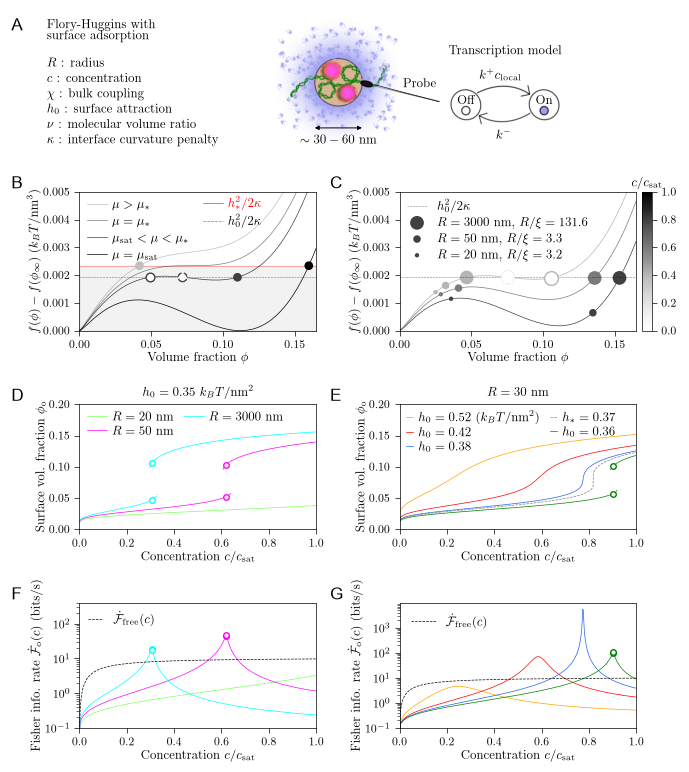

In [108]:
# A sits level with the top of its own band, beside the title; the others
# keep their reserved lines above each row
fig4.text(1.0 / W, yA_top / H, "A", usetex=False, fontfamily="Arial",
          fontsize=PT_LETTER, ha="left", va="top")
for x_let, rows in ((1.0, [(y1_let, "B"), (y2_let, "D"), (y3_let, "F")]),
                    (x_right - L2, [(y1_let, "C"), (y2_let, "E"), (y3_let, "G")])):
    for y_let, letter in rows:
        fig4.text(x_let / W, y_let / H, letter, usetex=False,
                  fontfamily="Arial", fontsize=PT_LETTER, ha="left", va="bottom")

OUT_DIR = os.path.join("figure_production", "fig4")
os.makedirs(OUT_DIR, exist_ok=True)
path = os.path.join(OUT_DIR, "fig4.pdf")
fig4.savefig(path, format="pdf", transparent=True)
# no bbox_inches: that would re-crop the page and lose \textwidth.
# transparent=True: the artwork is composited UNDER this layer (below), and
# matplotlib's white figure patch would otherwise cover it.
print("Saved figure to", path)

# ---------------------------------------------------------------------------
# Panel A's cartoon, composited in as vector
# ---------------------------------------------------------------------------
# The matplotlib figure carries only panel A's text; the artwork is the
# Illustrator drawing in fig4/fig4_cartoon.svg. It is stamped into the
# saved PDF rather than rasterised into the figure, so it stays vector.
#
# Sizing follows the reference assembly (225 x 237 pt): the cartoon's COLOURED
# extent -- the only part of panel A that is not text, hence the only landmark
# the two files share -- runs from 39.84% to 80.32% of the figure width, its
# top 1.80 pt below the figure's top edge at that page size. Measured there and
# in the SVG by thresholding colour saturation; the two aspect ratios agree to
# 1% (2.456 vs 2.482), which is what confirms it is the same drawing.
# CART_*, VB_* and INK are set with the rest of the geometry, so the labels in
# panel A and the artwork itself are placed from one set of numbers.
CARTOON = os.path.join(OUT_DIR, "fig4_cartoon.svg")


def _cairosvg():
    """The cairosvg module, or None if it cannot actually be used. A plain
    `pip install cairosvg` on macOS leaves it importable but unusable -- the
    cairo C library is missing and cairocffi raises OSError, not ImportError --
    so every use below falls back to Inkscape on any failure, not just on a
    missing module.

    Homebrew's cairo (`brew install cairo`) lives in /opt/homebrew/lib, which
    the python.org Python never searches; cairocffi locates it through
    ctypes.util.find_library, so point that at Homebrew's copy before the
    import. (DYLD_FALLBACK_LIBRARY_PATH would also do, but macOS strips DYLD_*
    variables on their way through system binaries, so it rarely reaches the
    kernel.)"""
    import ctypes.util
    brew = "/opt/homebrew/lib/libcairo.2.dylib"
    if os.path.exists(brew) and not getattr(ctypes.util, "_brew_cairo", False):
        _find = ctypes.util.find_library
        ctypes.util.find_library = lambda name: (
            brew if name in ("cairo-2", "cairo", "libcairo-2") else _find(name))
        ctypes.util._brew_cairo = True
    try:
        import cairosvg
        return cairosvg
    except Exception:
        return None


def _inkscape():
    """Inkscape's command line. On macOS it ships as an app bundle and is not
    on PATH, so look there too before giving up."""
    import shutil
    exe = shutil.which("inkscape")
    if exe:
        return exe
    for cand in ("/Applications/Inkscape.app/Contents/MacOS/inkscape",
                 os.path.expanduser(
                     "~/Applications/Inkscape.app/Contents/MacOS/inkscape")):
        if os.path.exists(cand):
            return cand
    return None


def svg_to_pdf(svg_path, pdf_path):
    """SVG -> PDF. The page box is NOT assumed: cairosvg writes it at 0.75x the
    viewBox (96 -> 72 dpi) and ignores output_width for PDF output, and other
    converters differ again, so the caller reads the box back and rescales."""
    cs = _cairosvg()
    if cs is not None:
        try:
            cs.svg2pdf(url=svg_path, write_to=pdf_path)
            return "cairosvg"
        except Exception:
            pass
    import subprocess
    exe = _inkscape()
    if exe:
        subprocess.run([exe, svg_path, "--export-type=pdf",
                        "--export-area-page", "--export-filename=" + pdf_path],
                       check=True, capture_output=True)
        return "inkscape"
    raise RuntimeError(
        "no working SVG converter. Either install Inkscape, or make cairosvg "
        "usable -- `pip install cairosvg` alone is not enough on macOS, it also "
        "needs the cairo C library (`brew install cairo`).")


def stamp_cartoon(page_pdf, svg_path):
    from pypdf import PdfReader, PdfWriter, Transformation
    import shutil, tempfile
    # the intermediate PDF goes to a scratch directory, not beside the
    # artwork: it is not a deliverable and must not litter the repo
    _scratch = tempfile.mkdtemp()
    tmp = os.path.join(_scratch, "cartoon.pdf")
    how = svg_to_pdf(svg_path, tmp)

    base = PdfReader(page_pdf).pages[0]
    art = PdfReader(tmp).pages[0]

    # viewBox units -> the converted page's own points
    box = art.mediabox
    f = float(box.width) / VB_W
    page_h = float(box.height)

    scale = CART_S / f                      # ... -> figure points
    tx = CART_X0F * W - scale * f * INK[0]
    # the SVG's y runs downwards from the viewBox top, the PDF's upwards from
    # the page bottom, so the ink top sits at page_h - f*INK[1]
    ty = (H - CART_TOP_PT) - scale * (page_h - f * INK[1])
    # The artwork goes UNDERNEATH the figure, not over it: merging it on top
    # puts its backdrop above panel A's labels and the size bar, which some
    # viewers then render as a white box that hides them. So start from an
    # empty page of the right size, lay the drawing down, and put the
    # (transparent) matplotlib layer over it.
    from pypdf import PageObject
    out = PageObject.create_blank_page(width=W, height=H)
    out.merge_transformed_page(art, Transformation().scale(scale).translate(tx, ty))
    out.merge_page(base)
    w = PdfWriter(); w.add_page(out)
    with open(page_pdf, "wb") as fh:
        w.write(fh)
    shutil.rmtree(_scratch, ignore_errors=True)
    print("cartoon (%s, page %.1f x %.1f pt): drawn %.1f x %.1f pt at x %.1f, "
          "%.1f pt from the top"
          % (how, float(box.width), page_h, CART_S * (INK[2] - INK[0]),
             CART_S * (INK[3] - INK[1]), CART_X0F * W, CART_TOP_PT))


def _missing_deps():
    """Both converters and the compositor, checked together, so a missing one
    is reported once with the command that fixes it rather than as a traceback
    halfway through."""
    import importlib.util as iu
    import shutil
    missing = []
    if iu.find_spec("pypdf") is None:
        missing.append("pypdf")
    if _cairosvg() is None and _inkscape() is None:
        missing.append("cairosvg")
    return missing


if not os.path.exists(CARTOON):
    print("no cartoon at", CARTOON, "-- panel A left as text only")
else:
    _missing = _missing_deps()
    if _missing:
        print("\n".join([
            "",
            "Panel A's artwork was NOT added: missing " + ", ".join(_missing) + ".",
            "The rest of the figure is complete and saved; only the cartoon is",
            "absent. To add it:",
            "",
            "    pip install " + " ".join(_missing),
            "",
            "cairosvg needs the cairo library (macOS: brew install cairo). If that",
            "is awkward, installing Inkscape works instead -- the notebook uses its",
            "command line as a fallback. pypdf is pure Python and always needed.",
            "",
        ]))
    else:
        stamp_cartoon(path, CARTOON)

# ---------------------------------------------------------------------------
# Inline preview
# ---------------------------------------------------------------------------
# The artwork lives in the saved PDF, not in the matplotlib figure, so a plain
# display() would show panel A empty. Add a RASTER copy of it to the figure now
# -- after savefig, so the PDF keeps the vector version -- purely so the
# notebook shows what was written. zorder puts it behind panel A's type.
def svg_to_png(svg_path, width_px):
    """SVG -> PNG bytes, by whichever converter is here. Preview only."""
    height_px = max(int(width_px * VB_H / VB_W), 1)
    cs = _cairosvg()
    if cs is not None:
        try:
            return cs.svg2png(url=svg_path, output_width=width_px,
                              output_height=height_px)
        except Exception:
            pass
    exe = _inkscape()
    if exe is None:
        return None
    import subprocess, tempfile
    tmp = os.path.join(tempfile.mkdtemp(), "cartoon_preview.png")
    subprocess.run([exe, svg_path, "--export-type=png", "--export-area-page",
                    "--export-width=%d" % width_px,
                    "--export-filename=" + tmp],
                   check=True, capture_output=True)
    with open(tmp, "rb") as fh:
        data = fh.read()
    os.remove(tmp)
    return data


def preview_cartoon(dpi=300):
    import io
    import matplotlib.image as mpimg

    px = max(int(CART_S * VB_W / 72 * dpi), 1)
    buf = svg_to_png(CARTOON, px)
    if buf is None:
        return False

    # the whole viewBox, mapped through the same transform as the stamped art
    x0 = CART_X0F * W + CART_S * (0 - INK[0])
    y0_top = CART_TOP_PT + CART_S * (0 - INK[1])
    w_pt, h_pt = CART_S * VB_W, CART_S * VB_H
    ax = fig4.add_axes([x0 / W, (H - y0_top - h_pt) / H, w_pt / W, h_pt / H],
                       zorder=-1)
    ax.imshow(mpimg.imread(io.BytesIO(buf), format="png"), interpolation="bilinear")
    ax.set_axis_off()
    ax.patch.set_alpha(0)
    return True


if os.path.exists(CARTOON) and not preview_cartoon():
    print("(no inline preview: neither cairosvg nor Inkscape found)")

# The figure is created in one cell and drawn across several, so Jupyter never
# auto-displays it (the inline backend only shows figures created in the cell
# being run). Display it explicitly.
from IPython.display import display
display(fig4)